MÁSTER BIG DATA & DATA ENGINEERING

# Validación del paquete `traficFines`

Ejemplos e instrucciones para comprobar que las clases `Cache`, `CacheUrl` y `MadridFines` funcionan
correctamente y lanzan las excepciones esperadas (`CacheError`, `MadridError`, `ValueError`).

**Cómo usarlo**

1. Instalar el paquete: `pip install dist/traficfines-1.0.0-py3-none-any.whl` (o `uv sync` en la raíz del proyecto).
2. Abrir el cuaderno con el kernel de ese entorno y ejecutar todas las celdas (*Run All*).

Cada comprobación usa `assert`: si una celda termina sin error, la comprobación ha pasado.
Las secciones 1 y 2 no necesitan internet (la caché se guarda en una carpeta temporal y las descargas se simulan).
La sección 3 usa el portal de datos abiertos de Madrid; la primera vez descarga dos ficheros de unos 60 MB.

Las pruebas exhaustivas del paquete están en la carpeta `pruebas/` (`uv run pytest`).

## 0. Preparación

In [1]:
import tempfile
from pathlib import Path
from unittest.mock import Mock, patch

from IPython.display import Image, display

import traficFines.cache as modulo_cache
from traficFines.cache import Cache, CacheUrl, CacheError
from traficFines.madridFines import MadridFines, MadridError


def comprobar_excepcion(excepcion, funcion, *args):
    """Comprueba que funcion(*args) lanza `excepcion` y muestra su mensaje."""
    try:
        funcion(*args)
    except excepcion as e:
        print(f"✔ {excepcion.__name__}: {e}")
        return
    raise AssertionError(f"Se esperaba {excepcion.__name__}")


# Las secciones 1 y 2 guardan la caché en una carpeta temporal en lugar de ~/.my_cache.
CACHE_DIR_ORIGINAL = modulo_cache.CACHE_DIR
modulo_cache.CACHE_DIR = Path(tempfile.mkdtemp())

## 1. Clase `Cache`

Guarda texto en disco dentro de la carpeta `CACHE_DIR / app_name`.

In [2]:
cache = Cache("validacion", obsolescence=7)
print("cache_dir:", cache.cache_dir)

cache.set("saludo", "Hola, Madrid")
assert cache.exists("saludo")
assert cache.load("saludo") == "Hola, Madrid"
print(f"Edad del dato: {cache.how_old('saludo'):.1f} ms")

cache.delete("saludo")
assert not cache.exists("saludo")
cache.delete("saludo")   # borrar un dato inexistente no lanza excepción

cache.set("a", "1"); cache.set("b", "2")
cache.clear()
assert not cache.exists("a") and not cache.exists("b")
print("✔ set, exists, load, how_old, delete y clear funcionan")

cache_dir: /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/tmpf5gdfjuw/validacion
Edad del dato: 0.1 ms
✔ set, exists, load, how_old, delete y clear funcionan


Excepciones: parámetros inválidos, datos inexistentes y atributos de solo lectura.

In [3]:
comprobar_excepcion(CacheError, Cache, "", 7)          # app_name vacío
comprobar_excepcion(CacheError, Cache, "app", -1)      # obsolescence negativo
comprobar_excepcion(CacheError, cache.load, "no_existe")
comprobar_excepcion(CacheError, cache.how_old, "no_existe")
comprobar_excepcion(AttributeError, setattr, cache, "cache_dir", "/otra")

✔ CacheError: app_name debe ser un string no vacío
✔ CacheError: obsolescence debe ser un entero >= 0
✔ CacheError: No existe ningún dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/tmpf5gdfjuw/validacion/no_existe
✔ CacheError: No existe dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/tmpf5gdfjuw/validacion/no_existe
✔ AttributeError: property 'cache_dir' of 'Cache' object has no setter


## 2. Clase `CacheUrl`

Guarda el contenido de una URL usando como nombre el hash MD5 de la URL y sus parámetros.
Aquí `requests.get` se simula para no depender de internet y poder contar las descargas.

In [4]:
cache_url = CacheUrl("validacion_url", obsolescence=7)
url = "https://ejemplo.test/datos.csv"
respuesta_ok = Mock(status_code=200, content=b"A;B\n1;2")

with patch.object(modulo_cache.requests, "get", return_value=respuesta_ok) as get_simulado:
    assert cache_url.get(url) == "A;B\n1;2"
    assert cache_url.get(url) == "A;B\n1;2"     # segunda vez: se lee de la caché

assert get_simulado.call_count == 1
assert cache_url.exists(url) and cache_url.load(url) == "A;B\n1;2"
cache_url.delete(url)
assert not cache_url.exists(url)
print("✔ get descarga una sola vez; exists, load y delete reciben la URL")

✔ get descarga una sola vez; exists, load y delete reciben la URL


In [5]:
with patch.object(modulo_cache.requests, "get", return_value=Mock(status_code=404)):
    comprobar_excepcion(CacheError, cache_url.get, "https://ejemplo.test/no_existe.csv")

comprobar_excepcion(CacheError, cache_url.load, "https://ejemplo.test/no_existe.csv")

# Fin de las pruebas sin red: la caché vuelve a su carpeta por defecto (~/.my_cache).
modulo_cache.CACHE_DIR = CACHE_DIR_ORIGINAL

✔ CacheError: Se obtuvo error al tratar de obtener información de https://ejemplo.test/no_existe.csv, con código de estado 404
✔ CacheError: No existe ningún dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/tmpf5gdfjuw/validacion_url/d7ac933192ad7c606d87cd29f7b03deb


## 3. Clase `MadridFines` (requiere internet)

Usa la caché `~/.my_cache/validacion` con una validez de 30 días: solo la primera ejecución descarga los ficheros.

### 3.1 `get_url` y excepciones

In [6]:
print(MadridFines.get_url(2023, 5))

comprobar_excepcion(MadridError, MadridFines.get_url, 2010, 1)   # mes no publicado

multas = MadridFines("validacion", obsolescence=30)
comprobar_excepcion(ValueError, multas.add, 2023, 13)            # mes fuera de rango
comprobar_excepcion(MadridError, multas.fines_calificacion)      # todavía no hay datos

https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-36-multas-circulacion-detalle-csv/download/210104-36-multas-circulacion-detalle-csv.csv


✔ MadridError: No se encontró el recurso para Enero de 2010 en https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/downloads.
✔ ValueError: Mes no válido: 13
✔ MadridError: No hay datos cargados. Usa add() antes de analizar.


### 3.2 `add`: carga, limpieza y control de duplicados

In [7]:
multas.add(2019, 5)
multas.add(2023, 5)
filas = len(multas.data)

multas.add(2023, 5)   # ya cargado: no hace nada
assert len(multas.data) == filas
assert multas.loaded == [(5, 2019), (5, 2023)]

# clean: columnas sin espacios, valores numéricos e índice fecha a partir de ANIO, MES y HORA (HH.MM).
assert multas.data.index.name == "fecha"
assert multas.data["VEL_LIMITE"].dtype.kind == "f"
print(f"{filas:,} multas cargadas | loaded = {multas.loaded}")
display(multas.data.head(3))

405,989 multas cargadas | loaded = [(5, 2019), (5, 2023)]


,CALIFICACION,LUGAR,MES,ANIO,HORA,IMP_BOL,DESCUENTO,PUNTOS,DENUNCIANTE,HECHO-BOL,VEL_LIMITE,VEL_CIRCULA,COORDENADA_X,COORDENADA_Y,COORDENADA-X,COORDENADA-Y
fecha,,,,,,,,,,,,,,,,
2019-05-01 19:10:00,GRAVE,ARROYO VALDECELADA,5,2019,19.10,200.0,SI,0,POLICIA MUNICIPAL,ESTACIONAR EN CARRIL DECIRCULACIÓN OBSTACULIZA...,NaN,NaN,NaN,NaN,NaN,NaN
2019-05-01 11:00:00,GRAVE,ALESANCO-SANCHEZ PRECIADO,5,2019,11.00,200.0,SI,0,POLICIA MUNICIPAL,ESTACIONAR EN CARRIL DECIRCULACIÓN OBSTACULIZA...,NaN,NaN,NaN,NaN,NaN,NaN
2019-05-01 11:01:00,LEVE,ALESANCO-SANCHEZ PRECIADO,5,2019,11.01,90.0,SI,0,POLICIA MUNICIPAL,ESTACIONAR EN CARRIL DE CIRCULACIÓN.,NaN,NaN,NaN,NaN,NaN,NaN


### 3.3 Análisis

`fines_calificacion` debe reproducir la tabla del enunciado para mayo de 2019 y de 2023.

In [8]:
tabla = multas.fines_calificacion()
display(tabla)
assert tabla.loc[(5, 2019)].tolist() == [61124, 111017, 747]
assert tabla.loc[(5, 2023)].tolist() == [137561, 94448, 1092]
print("✔ Coincide con el enunciado")

CALIFICACION   GRAVE    LEVE  MUY GRAVE
MES ANIO                               
5   2019       61124  111017        747
    2023      137561   94448       1092

✔ Coincide con el enunciado


`total_payments`: el importe máximo supone que nadie paga con descuento; el mínimo, que todas las multas con
`DESCUENTO = "SI"` se pagan con el 50 %.

In [9]:
importes = multas.total_payments()
display(importes)
assert (importes["IMPORTE_MINIMO"] <= importes["IMPORTE_MAXIMO"]).all()

IMPORTE_MAXIMO  IMPORTE_MINIMO
MES ANIO                                
5   2019      17207760.0       8603880.0
    2023      30764540.0      15382270.0

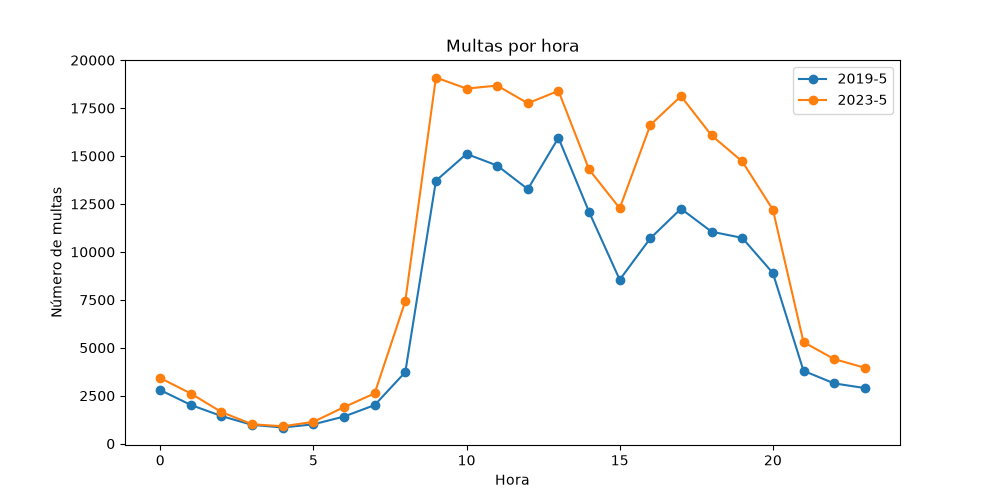

In [10]:
multas.fines_hour("evolucion_multas.png")
display(Image("evolucion_multas.png", width=700))

Para borrar los datos descargados de la caché: `multas.clean_cache()`.

---

*Este cuaderno se ha elaborado con ayuda de una herramienta de inteligencia artificial (Claude, de Anthropic).*